# Linear Regression Lab: Simple & Multiple Regression

**Goal:** predict a continuous value (disease progression) and interpret the regression coefficients.

**Dataset:** scikit-learn's built-in *Diabetes* dataset: 442 patients, 10 baseline features, and a target measuring disease progression one year later.

**Plan**
1. Explore the data and correlations
2. Simple linear regression (1 feature)
3. Multiple linear regression (all features)
4. Analyze coefficients (size, significance, multicollinearity)

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
np.random.seed(42)

## 1. Load and explore the data

In [22]:
data = load_diabetes(as_frame=True, scaled=False)   # original units
df = data.frame.rename(columns={"target": "progression"})
print(df.shape)
df.head()

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


In [23]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00


Feature meanings: `age`, `sex`, `bmi` (body mass index), `bp` (blood pressure), and `s1`–`s6` (blood serum measurements such as cholesterol and glucose). The target `progression` is what we want to predict.

### Correlation heatmap

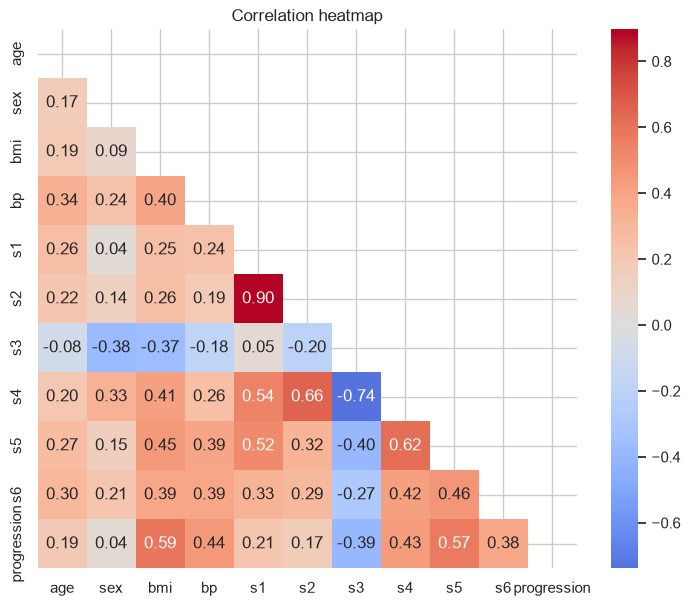

In [24]:
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap")
plt.show()

Look at the last row: `bmi` and `s5` have the strongest correlation with the target. Also note that `s1` and `s2` are highly correlated with each other. This is **multicollinearity**, which will affect coefficient interpretation later.

In [25]:
corr["progression"].drop("progression").sort_values(ascending=False).round(3)

bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: progression, dtype: float64

### Distribution of the target and feature relationships

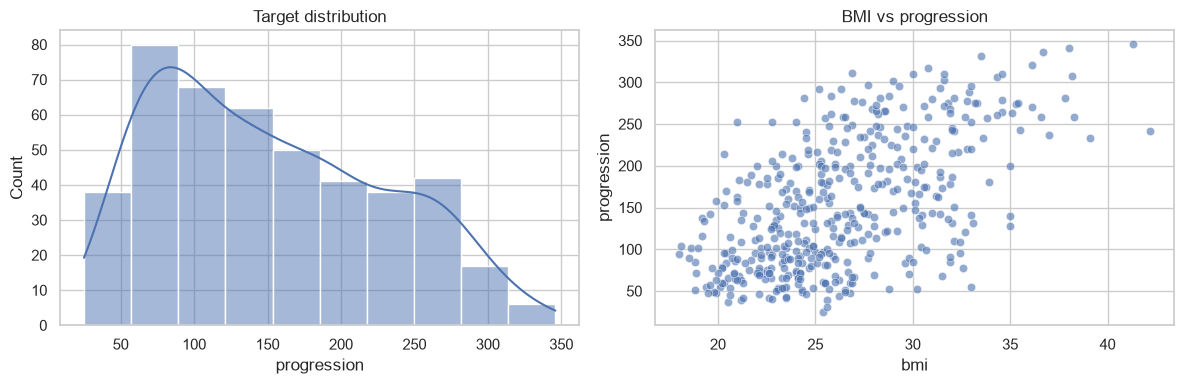

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["progression"], kde=True, ax=axes[0])
axes[0].set_title("Target distribution")
sns.scatterplot(data=df, x="bmi", y="progression", ax=axes[1], alpha=0.6)
axes[1].set_title("BMI vs progression")
plt.tight_layout()
plt.show()

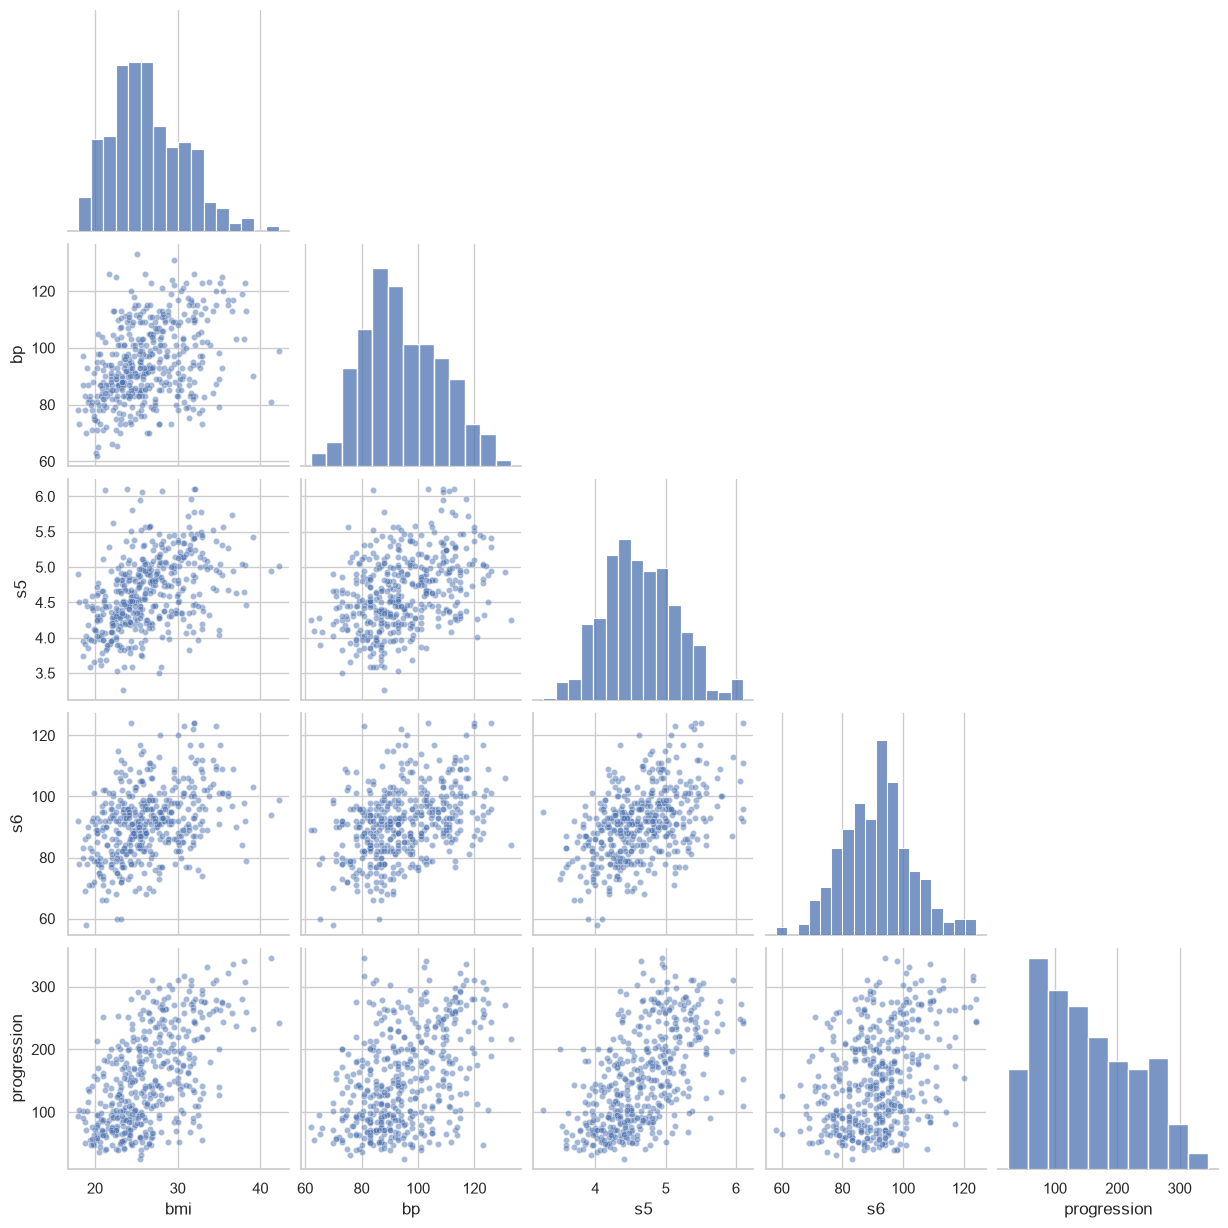

In [27]:
sns.pairplot(df[["bmi", "bp", "s5", "s6", "progression"]], corner=True, plot_kws={"alpha": 0.5, "s": 20})
plt.show()

## 2. Simple linear regression

Model: $\hat{y} = \beta_0 + \beta_1 x$

We use the single feature most correlated with the target. The least-squares solution has a closed form:

$$\beta_1 = \frac{\text{Cov}(x, y)}{\text{Var}(x)}, \qquad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

In [28]:
best_feature = corr["progression"].drop("progression").abs().idxmax()
print("Chosen feature:", best_feature)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
x_tr, y_tr = train_df[best_feature].values, train_df["progression"].values
x_te, y_te = test_df[best_feature].values, test_df["progression"].values

# Manual (closed-form) fit
b1 = np.cov(x_tr, y_tr, ddof=1)[0, 1] / np.var(x_tr, ddof=1)
b0 = y_tr.mean() - b1 * x_tr.mean()
print(f"Manual:  intercept={b0:.3f}, slope={b1:.3f}")

# scikit-learn fit (should match)
slr = LinearRegression().fit(x_tr.reshape(-1, 1), y_tr)
print(f"sklearn: intercept={slr.intercept_:.3f}, slope={slr.coef_[0]:.3f}")

Chosen feature: bmi
Manual:  intercept=-131.874, slope=10.763
sklearn: intercept=-131.874, slope=10.763


**Interpretation:** the slope is the expected change in `progression` for a one-unit increase in the feature, and the intercept is the predicted value when the feature is 0.

In [29]:
y_pred_s = slr.predict(x_te.reshape(-1, 1))

def report(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name}: R2={r2_score(y_true, y_pred):.3f}  RMSE={rmse:.2f}  MAE={mean_absolute_error(y_true, y_pred):.2f}")

report("Simple LR (test)", y_te, y_pred_s)

Simple LR (test): R2=0.233  RMSE=63.73  MAE=52.26


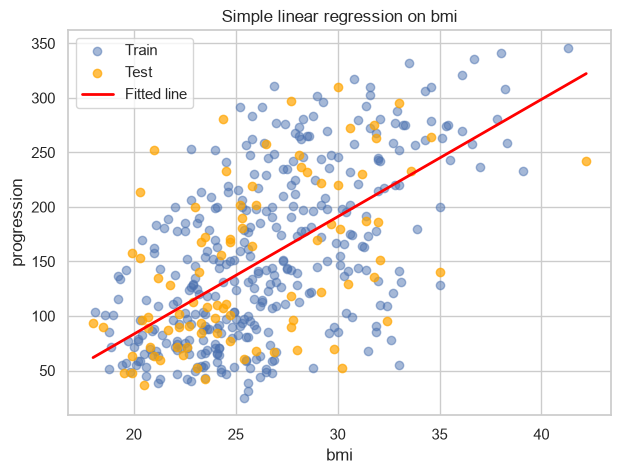

In [30]:
xs = np.linspace(df[best_feature].min(), df[best_feature].max(), 100)
plt.figure(figsize=(7, 5))
plt.scatter(x_tr, y_tr, alpha=0.5, label="Train")
plt.scatter(x_te, y_te, alpha=0.7, color="orange", label="Test")
plt.plot(xs, slr.predict(xs.reshape(-1, 1)), color="red", lw=2, label="Fitted line")
plt.xlabel(best_feature); plt.ylabel("progression")
plt.title(f"Simple linear regression on {best_feature}")
plt.legend(); plt.show()

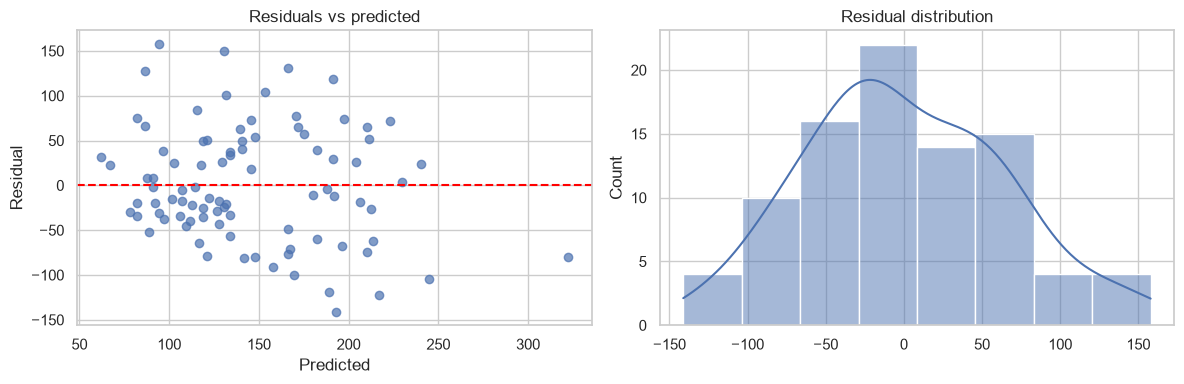

In [31]:
resid = y_te - y_pred_s
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_pred_s, resid, alpha=0.7)
axes[0].axhline(0, color="red", ls="--")
axes[0].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs predicted")
sns.histplot(resid, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")
plt.tight_layout(); plt.show()

A good fit has residuals scattered randomly around 0 with no pattern, and roughly bell-shaped. One feature explains only part of the variation, so let's use all of them.

## 3. Multiple linear regression

Model: $\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$

Each coefficient is the effect of its feature **holding all other features constant**.

In [32]:
features = [c for c in df.columns if c != "progression"]
X = df[features]
y = df["progression"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mlr = LinearRegression().fit(X_train, y_train)
y_pred_m = mlr.predict(X_test)

report("Simple LR   (test)", y_te, y_pred_s)
report("Multiple LR (test)", y_test, y_pred_m)

Simple LR   (test): R2=0.233  RMSE=63.73  MAE=52.26
Multiple LR (test): R2=0.453  RMSE=53.85  MAE=42.79


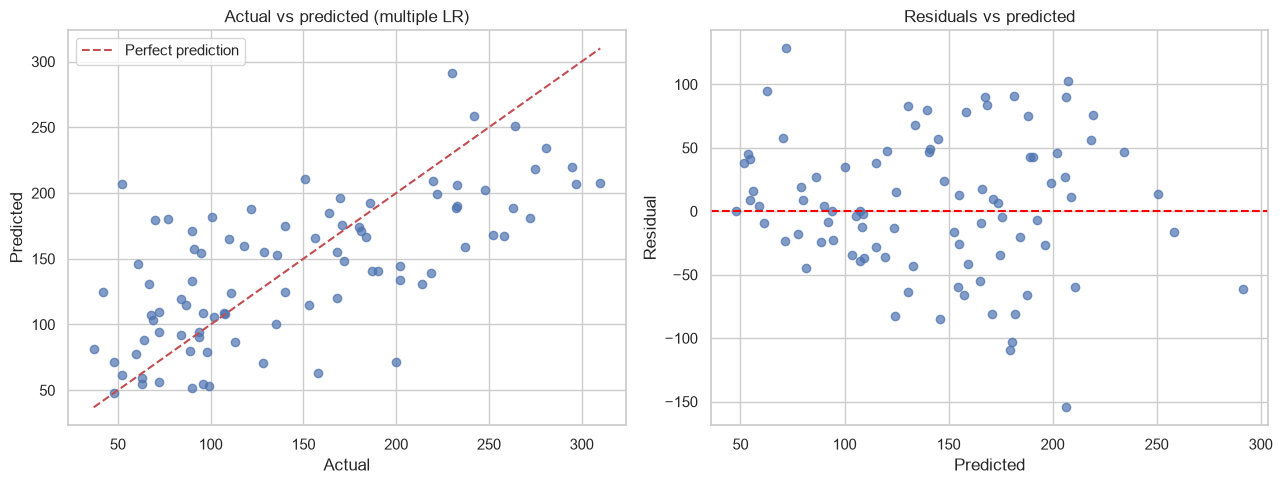

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred_m, alpha=0.7)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set(xlabel="Actual", ylabel="Predicted", title="Actual vs predicted (multiple LR)")
axes[0].legend()

resid_m = y_test - y_pred_m
axes[1].scatter(y_pred_m, resid_m, alpha=0.7)
axes[1].axhline(0, color="red", ls="--")
axes[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs predicted")
plt.tight_layout(); plt.show()

## 4. Analyzing the coefficients

### 4.1 Raw coefficients
These are in the original units of each feature, so they are **not directly comparable** (e.g. `bmi` vs `s1` have very different scales).

In [34]:
coef_df = pd.DataFrame({"feature": features, "coefficient": mlr.coef_}).sort_values("coefficient")
print("Intercept:", round(mlr.intercept_, 3))
coef_df.round(3)

Intercept: -341.378


,feature,coefficient
1,sex,-23.064
4,s1,-1.282
0,age,0.138
9,s6,0.202
6,s3,0.602
5,s2,0.811
3,bp,1.197
2,bmi,5.846
7,s4,10.160
8,s5,67.109


### 4.2 Standardized coefficients
Standardizing features (mean 0, std 1) puts coefficients on the same scale: each shows the change in `progression` per **one standard deviation** increase in the feature. Now we can compare importance.

Test R2 (same as before, scaling doesn't change predictions): 0.453


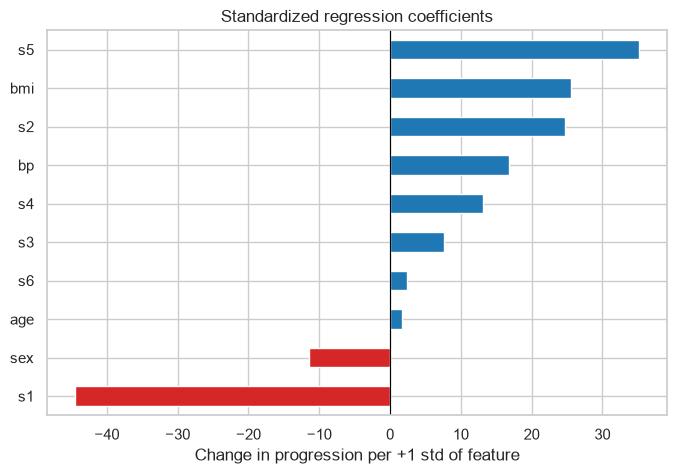

In [35]:
scaler = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)
mlr_s = LinearRegression().fit(Xtr_s, y_train)
print("Test R2 (same as before, scaling doesn't change predictions):",
      round(r2_score(y_test, mlr_s.predict(Xte_s)), 3))

std_coef = pd.Series(mlr_s.coef_, index=features).sort_values()
plt.figure(figsize=(8, 5))
colors = ["tab:red" if v < 0 else "tab:blue" for v in std_coef]
std_coef.plot(kind="barh", color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Standardized regression coefficients")
plt.xlabel("Change in progression per +1 std of feature")
plt.show()

### 4.3 Statistical significance (statsmodels)
`statsmodels` gives p-values and confidence intervals. A small p-value (< 0.05) suggests the feature has a real linear relationship with the target, given the other features.

In [36]:
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:            progression   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           5.41e-50
Time:                        23:46:56   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             3834.
Df Residuals:                     342   BIC:                             3877.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -341.3782     74.073     -4.609      0.0

In [37]:
ci = ols.conf_int()
ci.columns = ["ci_low", "ci_high"]
summary = pd.concat([ols.params.rename("coef"), ci, ols.pvalues.rename("p_value")], axis=1).drop("const")
summary["significant"] = summary["p_value"] < 0.05
summary.round(4)

,coef,ci_low,ci_high,p_value,significant
age,0.1377,-0.3557,0.6311,0.5834,False
sex,-23.0645,-35.9206,-10.2083,0.0005,True
bmi,5.8464,4.2149,7.4778,0.0000,True
bp,1.1971,0.7139,1.6803,0.0000,True
s1,-1.2817,-2.5026,-0.0607,0.0397,True
s2,0.8112,-0.3102,1.9325,0.1557,False
s3,0.6017,-1.0857,2.2890,0.4836,False
s4,10.1595,-3.2971,23.6162,0.1385,False
s5,67.1090,32.6055,101.6124,0.0002,True
s6,0.2016,-0.3967,0.7999,0.5079,False


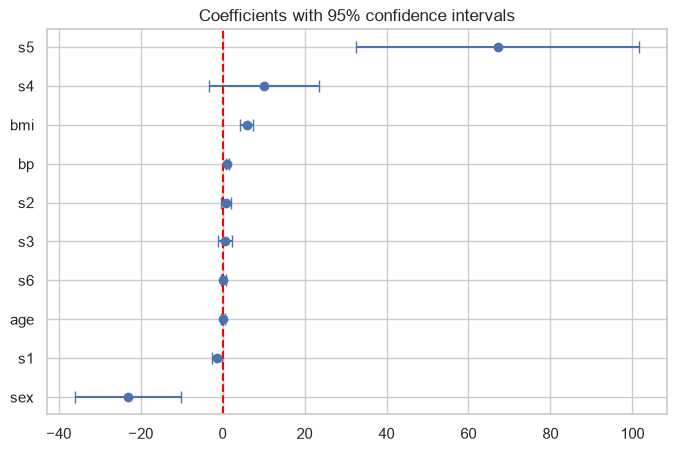

In [38]:
s = summary.sort_values("coef")
plt.figure(figsize=(8, 5))
plt.errorbar(s["coef"], range(len(s)),
             xerr=[s["coef"] - s["ci_low"], s["ci_high"] - s["coef"]],
             fmt="o", capsize=4)
plt.yticks(range(len(s)), s.index)
plt.axvline(0, color="red", ls="--")
plt.title("Coefficients with 95% confidence intervals")
plt.show()

If an interval crosses 0, we can't be confident that feature has an effect once the others are included.

### 4.4 Multicollinearity (VIF)
When features are strongly correlated, coefficients become unstable and hard to interpret, and may even take unexpected signs. The **Variance Inflation Factor** measures this; values above about 5–10 are a warning sign.

In [39]:
Xc = sm.add_constant(X_train)
vif = pd.DataFrame({
    "feature": Xc.columns,
    "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]
}).query("feature != 'const'").sort_values("VIF", ascending=False)
vif.round(2)

,feature,VIF
5,s1,55.25
6,s2,35.76
7,s3,14.29
9,s5,10.07
8,s4,9.33
3,bmi,1.57
10,s6,1.50
4,bp,1.42
2,sex,1.27
1,age,1.22


`s1`, `s2` (and often `s3`) have large VIFs, which matches the heatmap. Their individual coefficients should be interpreted cautiously, even though the model still predicts well overall.

## 5. Summary

In [40]:
results = pd.DataFrame({
    "Model": ["Simple (" + best_feature + ")", "Multiple (all 10 features)"],
    "Test R2": [r2_score(y_te, y_pred_s), r2_score(y_test, y_pred_m)],
    "Test RMSE": [np.sqrt(mean_squared_error(y_te, y_pred_s)), np.sqrt(mean_squared_error(y_test, y_pred_m))],
}).round(3)
results

,Model,Test R2,Test RMSE
0,Simple (bmi),0.233,63.732
1,Multiple (all 10 features),0.453,53.853


**Takeaways**
- Simple regression on one feature captures only part of the variation; adding features improves R² and lowers RMSE.
- Standardized coefficients show which features matter most (typically `s5` and `bmi` have the largest positive effects, and `bp` also contributes).
- Raw coefficients depend on units; p-values and confidence intervals show which effects are statistically reliable.
- Multicollinearity (high VIF) makes some coefficients unreliable even when predictions are good.
- Linear regression assumes a linear relationship, independent errors with constant variance, and roughly normal residuals. Check these using the residual plots.

**Try next:** Ridge/Lasso regression to handle multicollinearity, adding polynomial features, or cross-validation instead of a single split.